# Tutorial 9: Support Vector Machine (SVM)
## Maximum Margin Classification & Support Vector Regression on Formula 1 Data

---

### Objectives
1. **Mathematical Foundation**: Formulate margin maximization $\frac{2}{\|\mathbf{w}\|}$, soft margin slack variables $\xi_i$, and the regularization parameter $C$.
2. **Data Ingestion**: Extract race performance data from `results.csv`, `races.csv`, and `drivers.csv`.
3. **Linear vs. Non-Linear Kernels**: Compare Linear, RBF, and Polynomial kernels on Formula 1 outcome boundaries.
4. **Visualizing Decision Boundaries & Support Vectors**: Identify and plot the critical support vectors circled in gold.
5. **Hyperparameter Tuning (`GridSearchCV`)**: Optimize $C$ and $\gamma$ using cross-validation.
6. **Support Vector Regression (`SVR`)**: Model continuous lap speeds and finishing positions with an $\epsilon$-insensitive error tube.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


## 1. Data Ingestion & Preprocessing
We extract race results and driver telemetry from `results.csv`, `races.csv`, and `drivers.csv` to predict **Podium Finishes** ($1^{\text{st}} - 3^{\text{rd}}$ place).


In [2]:
results = pd.read_csv('results.csv')
races = pd.read_csv('races.csv')
drivers = pd.read_csv('drivers.csv')

# Filter modern era
races_sub = races[races['year'] >= 2004][['raceId', 'year', 'round', 'circuitId']]
f1_df = results.merge(races_sub, on='raceId')
f1_df = f1_df.merge(drivers[['driverId', 'dob', 'nationality']], on='driverId')

# Clean features
f1_df['grid'] = pd.to_numeric(f1_df['grid'], errors='coerce').fillna(20)
f1_df['laps'] = pd.to_numeric(f1_df['laps'], errors='coerce').fillna(0)
f1_df['fastestLapSpeed'] = pd.to_numeric(f1_df['fastestLapSpeed'], errors='coerce')
f1_df['fastestLapSpeed'] = f1_df['fastestLapSpeed'].fillna(f1_df['fastestLapSpeed'].median())
f1_df['driver_age'] = f1_df['year'] - pd.to_datetime(f1_df['dob'], errors='coerce').dt.year
f1_df['driver_age'] = f1_df['driver_age'].fillna(f1_df['driver_age'].median())

# Target: Podium Finish (1: Top 3, 0: Others)
f1_df['podium'] = (f1_df['positionOrder'] <= 3).astype(int)

# Stratified sample for responsive training and visualization
pos_samples = f1_df[f1_df['podium'] == 1].sample(min(sum(f1_df['podium'] == 1), 1500), random_state=42)
neg_samples = f1_df[f1_df['podium'] == 0].sample(min(sum(f1_df['podium'] == 0), 1500), random_state=42)
sample_df = pd.concat([pos_samples, neg_samples]).sample(frac=1.0, random_state=42).reset_index(drop=True)

features = ['grid', 'laps', 'fastestLapSpeed', 'driver_age', 'round']
X = sample_df[features]
y = sample_df['podium']

print(f"Sampled Dataset Shape: {X.shape}")
print(f"Target Distribution:\n{y.value_counts()}")
X.head()


Sampled Dataset Shape: (2841, 5)
Target Distribution:
podium
0    1500
1    1341
Name: count, dtype: int64


,grid,laps,fastestLapSpeed,driver_age,round
0,1.0,71,205.125,26,19
1,9.0,57,195.912,23,12
2,1.0,66,204.894,24,9
3,9.0,66,193.971,32,5
4,2.0,56,193.501,28,2


## 2. Standardization
SVM relies on Euclidean distance calculations to measure margins. Standardizing features ensures that dimensions with large magnitudes do not distort distance metrics.


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Training Samples: {X_train.shape[0]}, Test Samples: {X_test.shape[0]}")


Training Samples: 1988, Test Samples: 853


## 3. Kernel Comparison: Linear vs. RBF vs. Polynomial
We train Support Vector Classifiers with:
1. **Linear Kernel**: $K(\mathbf{x}, \mathbf{z}) = \mathbf{x}^T \mathbf{z}$
2. **Radial Basis Function (RBF)**: $K(\mathbf{x}, \mathbf{z}) = \exp(-\gamma \|\mathbf{x} - \mathbf{z}\|^2)$
3. **Polynomial Kernel**: $K(\mathbf{x}, \mathbf{z}) = (\gamma \mathbf{x}^T \mathbf{z} + 1)^3$


In [4]:
kernels = ['linear', 'rbf', 'poly']
models = {}
results_list = []

for k in kernels:
    clf = SVC(kernel=k, C=1.0, gamma='scale', random_state=42)
    clf.fit(X_train, y_train)
    models[k] = clf
    
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    n_sv = len(clf.support_vectors_)
    
    results_list.append({
        'Kernel': k.upper(),
        'Test Accuracy': f"{acc*100:.2f}%",
        'Total Support Vectors': n_sv,
        'Support Vector Ratio': f"{n_sv / len(X_train)*100:.1f}%"
    })

pd.DataFrame(results_list)


,Kernel,Test Accuracy,Total Support Vectors,Support Vector Ratio
0,LINEAR,83.59%,739,37.2%
1,RBF,83.82%,745,37.5%
2,POLY,82.30%,917,46.1%


## 4. Visualizing Decision Boundaries & Support Vectors
We train a 2D SVM using the two most influential features: **Starting Grid** and **Fastest Lap Speed**. Support vectors are highlighted with gold circles.


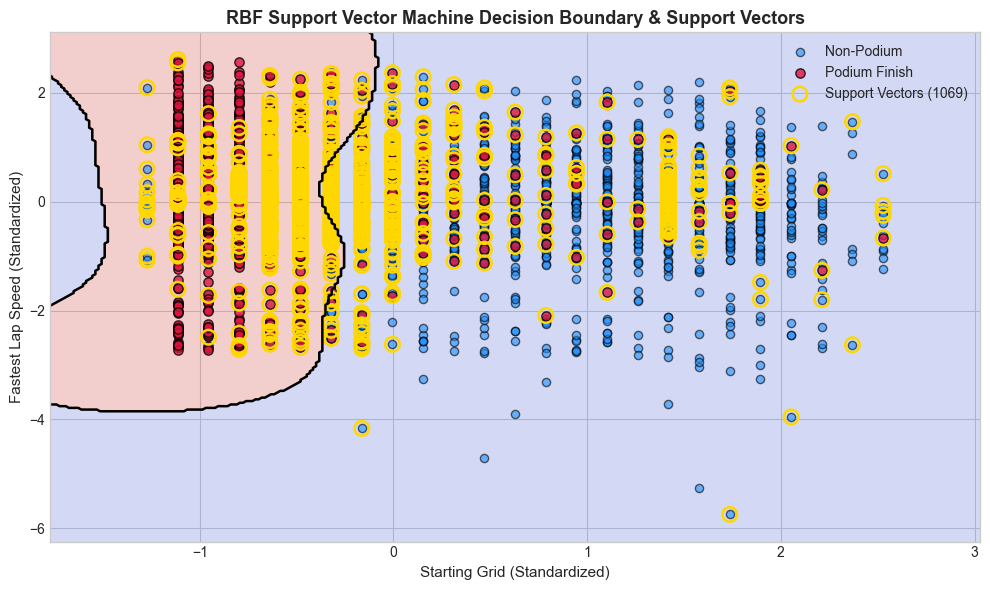

In [5]:
# 2D model on Grid vs FastestLapSpeed
X_2d = sample_df[['grid', 'fastestLapSpeed']].values
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

svm_2d = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_2d.fit(X_2d_scaled, y)

# Plotting function
fig, ax = plt.subplots(figsize=(10, 6))

x_min, x_max = X_2d_scaled[:, 0].min() - 0.5, X_2d_scaled[:, 0].max() + 0.5
y_min, y_max = X_2d_scaled[:, 1].min() - 0.5, X_2d_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax.contourf(xx, yy, Z, alpha=0.25, cmap='coolwarm')
ax.contour(xx, yy, Z, levels=[0.5], colors='k', linewidths=1.8)

# Scatter data points
ax.scatter(X_2d_scaled[y == 0, 0], X_2d_scaled[y == 0, 1], c='dodgerblue', edgecolor='k', s=35, alpha=0.6, label='Non-Podium')
ax.scatter(X_2d_scaled[y == 1, 0], X_2d_scaled[y == 1, 1], c='crimson', edgecolor='k', s=45, alpha=0.8, label='Podium Finish')

# Highlight support vectors
sv = svm_2d.support_vectors_
ax.scatter(sv[:, 0], sv[:, 1], s=110, facecolors='none', edgecolors='gold', linewidths=1.8, label=f'Support Vectors ({len(sv)})')

ax.set_title('RBF Support Vector Machine Decision Boundary & Support Vectors', fontsize=13, fontweight='bold')
ax.set_xlabel('Starting Grid (Standardized)', fontsize=11)
ax.set_ylabel('Fastest Lap Speed (Standardized)', fontsize=11)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


## 5. Hyperparameter Tuning with `GridSearchCV`
We optimize the regularization parameter **$C$** and kernel coefficient **$\gamma$** using 5-fold cross-validation.


In [6]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.1, 0.01],
    'kernel': ['linear', 'rbf']
}

grid_search = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print(f"Optimal Hyperparameters: {grid_search.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_*100:.2f}%")

best_svm = grid_search.best_estimator_
y_pred_best = best_svm.predict(X_test)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_best)*100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_best, target_names=['Non-Podium', 'Podium']))


Optimal Hyperparameters: {'C': 100, 'gamma': 0.01, 'kernel': 'rbf'}
Best Cross-Validation Accuracy: 86.12%
Test Accuracy: 84.99%

Classification Report:
              precision    recall  f1-score   support

  Non-Podium       0.87      0.85      0.86       450
      Podium       0.83      0.85      0.84       403

    accuracy                           0.85       853
   macro avg       0.85      0.85      0.85       853
weighted avg       0.85      0.85      0.85       853



## 6. Support Vector Regression (SVR)
Support Vector Regression fits continuous targets within an $\epsilon$-insensitive tube. Target: Predicting continuous finishing positions (`positionOrder`).


=== Support Vector Regression (SVR) ===


Root Mean Squared Error (RMSE): 3.80 finishing positions
R² Score: 0.668


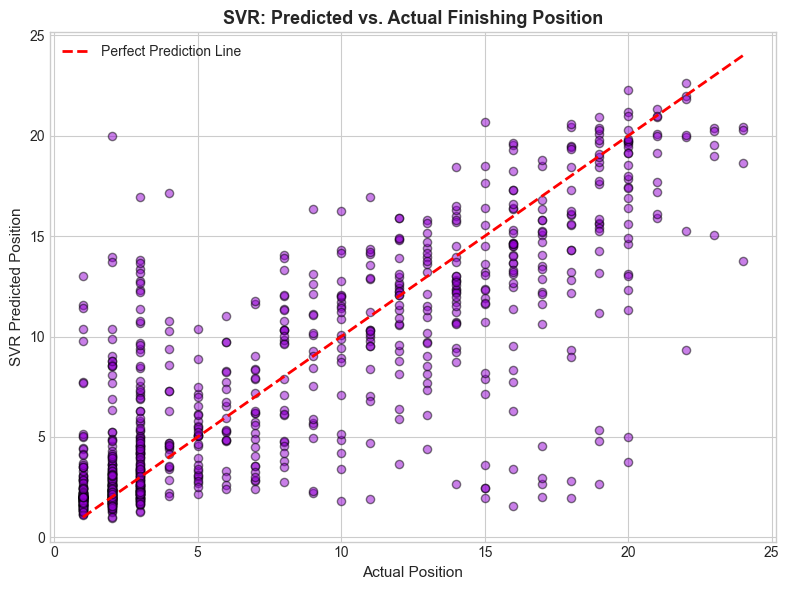

In [7]:
# Target: continuous race finishing position
y_pos = sample_df['positionOrder'].values
y_pos_train, y_pos_test, X_reg_train, X_reg_test = train_test_split(
    y_pos, X_scaled, test_size=0.3, random_state=42
)

# Fit SVR with RBF kernel and epsilon margin
svr = SVR(kernel='rbf', C=10.0, epsilon=1.0, gamma='scale')
svr.fit(X_reg_train, y_pos_train)

y_pos_pred = svr.predict(X_reg_test)
rmse = np.sqrt(mean_squared_error(y_pos_test, y_pos_pred))
r2 = r2_score(y_pos_test, y_pos_pred)

print("=== Support Vector Regression (SVR) ===")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} finishing positions")
print(f"R² Score: {r2:.3f}")

# Plot Predicted vs Actual
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_pos_test, y_pos_pred, alpha=0.5, color='darkviolet', edgecolor='k', s=35)
ax.plot([1, 24], [1, 24], 'r--', lw=2, label='Perfect Prediction Line')
ax.set_title('SVR: Predicted vs. Actual Finishing Position', fontsize=13, fontweight='bold')
ax.set_xlabel('Actual Position', fontsize=11)
ax.set_ylabel('SVR Predicted Position', fontsize=11)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


## 7. Summary & Key Takeaways
- **Margin Maximization**: SVM establishes an optimal separating hyperplane that resists overfitting even on overlapping telemetry.
- **Support Vectors**: Only points on the boundary or within the margin define the decision surface, making SVM memory-efficient during inference.
- **RBF Non-Linearity**: Successfully mapped complex multi-dimensional driver performance into separable hyperspace.
- **Support Vector Regression (SVR)**: The $\epsilon$-insensitive tube offers robust continuous estimation resistant to racing outliers.
